# Redes Neuronales Convolucionales sobre Fashion-MNIST

**Trabajo práctico — Conceptos de Inteligencia Artificial (Universidad de Palermo)**
Autor: Zaragoza Yago

Consigna: construir un modelo e implementarlo utilizando una CNN.

- **a.** Buscar y seleccionar un conjunto de datos.
- **b.** Programar (construir) la red neuronal.
- **c.** Realizar el proceso de aprendizaje.
- **d.** Realizar la validación del modelo utilizando ejemplos y cotejando el resultado.

Este notebook reúne el flujo completo de los scripts de `src/` (`datos.py`, `modelo.py`, `entrenar.py`,
`validar.py` y `predecir.py`). Se ejecuta de punta a punta con semilla fija 42. Es compatible con Google
Colab: si no encuentra la carpeta `archive/` con los datos, descarga los archivos idx del repositorio oficial.

In [1]:
# Configuración general: librerías, semilla y clases
import gzip
import json
import os
import platform
import random
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import sklearn
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

LADO = 28
CLASES = {0: "Remera/top", 1: "Pantalón", 2: "Buzo", 3: "Vestido", 4: "Abrigo",
          5: "Sandalia", 6: "Camisa", 7: "Zapatilla", 8: "Bolso", 9: "Bota"}
NUM_CLASES = len(CLASES)
SALIDAS = Path("salidas_notebook")
SALIDAS.mkdir(exist_ok=True)

print(f"Python {platform.python_version()} · TensorFlow {tf.__version__} · Keras {keras.__version__} · "
      f"NumPy {np.__version__} · scikit-learn {sklearn.__version__}")

Python 3.12.6 · TensorFlow 2.21.0 · Keras 3.15.1 · NumPy 2.5.4 · scikit-learn 1.9.1


## a. Selección del conjunto de datos

Se usa **Fashion-MNIST** (Zalando Research; Xiao, Rasul y Vollgraf, 2017; licencia MIT): 70.000 imágenes de
prendas en escala de grises de 28 × 28 píxeles, 60.000 de entrenamiento y 10.000 de prueba, en 10 clases
balanceadas. Se leen los archivos idx, idénticos a los del repositorio oficial (los CSV de la descarga de
Kaggle no reproducen la partición oficial; ver el informe).

Preprocesamiento: normalización de los píxeles a [0, 1], forma (n, 28, 28, 1) y etiquetas one-hot con
`to_categorical`, como en el video de la cátedra.

In [2]:
IDX = {"x_train": "train-images-idx3-ubyte", "y_train": "train-labels-idx1-ubyte",
       "x_test": "t10k-images-idx3-ubyte", "y_test": "t10k-labels-idx1-ubyte"}
URL_OFICIAL = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"


def buscar_idx(carpeta, nombre):
    """Ruta del archivo idx, comprimido (.gz) o no."""
    for candidato in (carpeta / nombre, carpeta / f"{nombre}.gz"):
        if candidato.exists():
            return candidato
    return None


def ubicar_datos():
    """Busca los idx localmente; si no están (por ejemplo, en Colab), los descarga del repo oficial."""
    candidatos = [os.environ.get("FASHION_MNIST_DIR"), "../../archive", "../archive", "archive", "datos_fashion_mnist"]
    for c in candidatos:
        if c and all(buscar_idx(Path(c), n) for n in IDX.values()):
            return Path(c), "local"
    destino = Path("datos_fashion_mnist")
    destino.mkdir(exist_ok=True)
    for n in IDX.values():
        urllib.request.urlretrieve(URL_OFICIAL + n + ".gz", destino / f"{n}.gz")
    return destino, "descargado del repositorio oficial"


def leer_idx(ruta, magico_esperado):
    """Lee un archivo idx (formato original de LeCun) comprimido o no."""
    abrir = gzip.open if ruta.suffix == ".gz" else open
    with abrir(ruta, "rb") as f:
        datos = f.read()
    magico = int.from_bytes(datos[0:4], "big")
    assert magico == magico_esperado, f"{ruta.name}: número mágico {magico}"
    n = int.from_bytes(datos[4:8], "big")
    if magico == 2051:
        filas, cols = int.from_bytes(datos[8:12], "big"), int.from_bytes(datos[12:16], "big")
        return np.frombuffer(datos, dtype=np.uint8, offset=16).reshape(n, filas * cols)
    return np.frombuffer(datos, dtype=np.uint8, offset=8).astype(np.int64)


origen, modo = ubicar_datos()
x_train = leer_idx(buscar_idx(origen, IDX["x_train"]), 2051)
y_train = leer_idx(buscar_idx(origen, IDX["y_train"]), 2049)
x_test = leer_idx(buscar_idx(origen, IDX["x_test"]), 2051)
y_test = leer_idx(buscar_idx(origen, IDX["y_test"]), 2049)

# Normalización a [0, 1] y un solo canal; etiquetas one-hot
x_train = (x_train.astype("float32") / 255.0).reshape(-1, LADO, LADO, 1)
x_test = (x_test.astype("float32") / 255.0).reshape(-1, LADO, LADO, 1)
y_train_cat = to_categorical(y_train, NUM_CLASES)
y_test_cat = to_categorical(y_test, NUM_CLASES)

# Verificaciones
assert x_train.shape == (60000, LADO, LADO, 1) and x_test.shape == (10000, LADO, LADO, 1)
assert 0.0 <= x_train.min() and x_train.max() <= 1.0 and not np.isnan(x_train).any()
assert np.bincount(y_train).tolist() == [6000] * NUM_CLASES
assert np.bincount(y_test).tolist() == [1000] * NUM_CLASES
print(f"Datos: {origen} ({modo})")
print(f"Entrenamiento {x_train.shape} · Prueba {x_test.shape} · verificaciones OK")

Datos: ..\..\archive (local)
Entrenamiento (60000, 28, 28, 1) · Prueba (10000, 28, 28, 1) · verificaciones OK


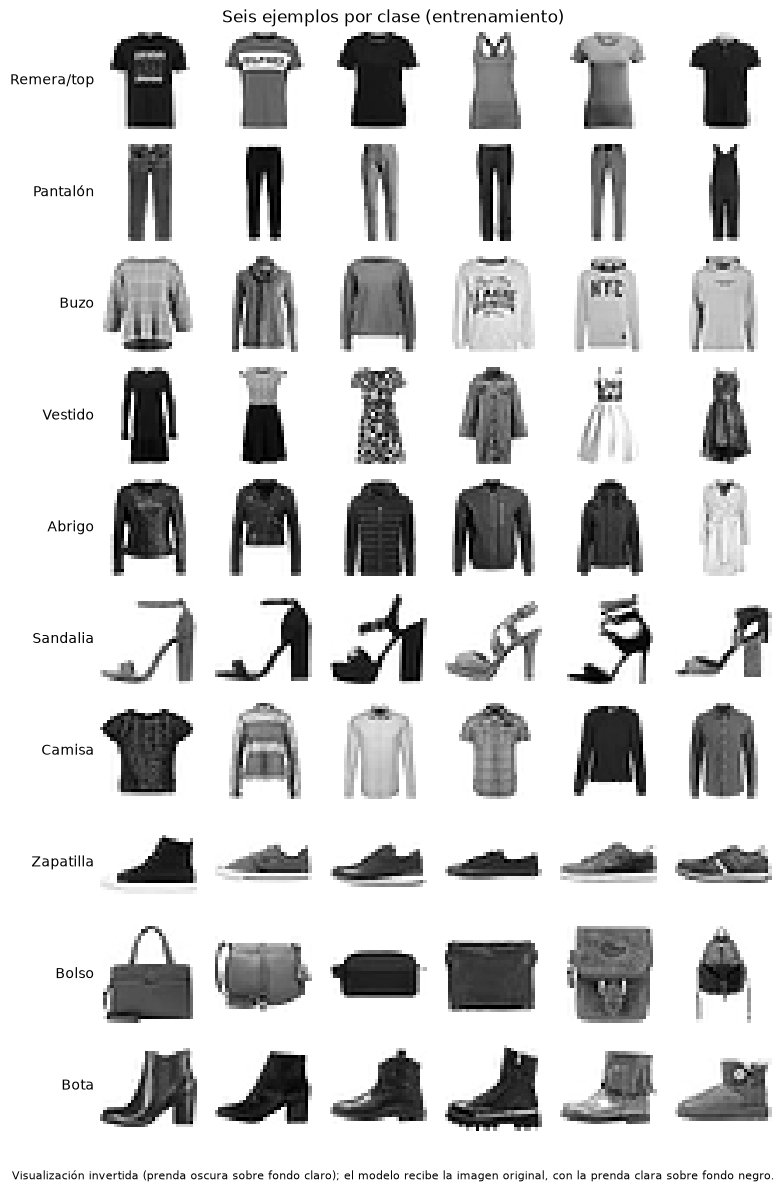

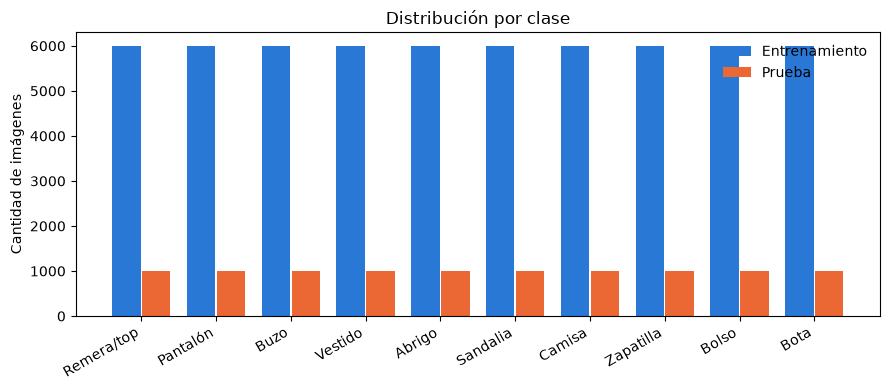

In [3]:
EPIGRAFE = ("Visualización invertida (prenda oscura sobre fondo claro); el modelo recibe la imagen original, "
            "con la prenda clara sobre fondo negro.")


def mostrar_imagen(eje, imagen, titulo=None):
    """Convención visual del TP: escala de grises invertida, sin ejes."""
    eje.imshow(np.asarray(imagen).reshape(LADO, LADO), cmap="gray_r", vmin=0, vmax=1)
    eje.set_xticks([]); eje.set_yticks([])
    for borde in eje.spines.values():
        borde.set_visible(False)
    if titulo:
        eje.set_title(titulo, fontsize=9)


rng = np.random.default_rng(SEMILLA)
fig, ejes = plt.subplots(NUM_CLASES, 6, figsize=(8, 12))
for c in range(NUM_CLASES):
    for j, i in enumerate(rng.choice(np.flatnonzero(y_train == c), size=6, replace=False)):
        mostrar_imagen(ejes[c, j], x_train[i])
    ejes[c, 0].set_ylabel(CLASES[c], rotation=0, ha="right", va="center")
fig.suptitle("Seis ejemplos por clase (entrenamiento)")
fig.text(0.5, 0.005, EPIGRAFE, ha="center", fontsize=8, wrap=True)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()

pos = np.arange(NUM_CLASES)
plt.figure(figsize=(9, 4))
plt.bar(pos - 0.2, np.bincount(y_train), 0.38, label="Entrenamiento", color="#2a78d6")
plt.bar(pos + 0.2, np.bincount(y_test), 0.38, label="Prueba", color="#eb6834")
plt.xticks(pos, [CLASES[c] for c in pos], rotation=30, ha="right")
plt.ylabel("Cantidad de imágenes"); plt.title("Distribución por clase"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()

## b. Construcción de la red

Modelo secuencial (`Sequential`) con la lógica de la CNN sobre MNIST del video de la cátedra y un bloque
convolucional más: dos bloques de convolución 3 × 3 con ReLU, agrupación máxima 2 × 2 y dropout, y luego
flatten, una capa totalmente conectada de 128 neuronas, dropout del 50 % y salida softmax de 10 clases.

In [4]:
def fijar_semilla(semilla=SEMILLA):
    random.seed(semilla)
    np.random.seed(semilla)
    tf.random.set_seed(semilla)


def construir_modelo():
    """CNN del trabajo. Se fija la semilla antes de construir, como en src/modelo.py."""
    fijar_semilla()
    modelo = keras.Sequential([
        # En Keras 3 la forma de entrada se declara con keras.Input (reemplaza a input_shape del video)
        keras.Input(shape=(LADO, LADO, 1), name="entrada"),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same", name="conv1_1"),
        layers.Conv2D(32, (3, 3), activation="relu", name="conv1_2"),
        layers.MaxPooling2D((2, 2), name="pool1"),
        layers.Dropout(0.25, name="drop1"),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv2_1"),
        layers.Conv2D(64, (3, 3), activation="relu", name="conv2_2"),
        layers.MaxPooling2D((2, 2), name="pool2"),
        layers.Dropout(0.25, name="drop2"),
        layers.Flatten(name="flatten"),
        layers.Dense(128, activation="relu", name="densa"),
        layers.Dropout(0.5, name="drop3"),
        layers.Dense(NUM_CLASES, activation="softmax", name="salida"),
    ], name="cnn_fashion_mnist")
    modelo.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return modelo


# Partición de validación: 54.000 / 6.000, estratificada (el test oficial no se toca hasta la etapa d)
idx_entr, idx_val = train_test_split(np.arange(len(y_train)), test_size=6000, stratify=y_train,
                                     random_state=SEMILLA)
assert np.bincount(y_train[idx_val]).tolist() == [600] * NUM_CLASES

modelo = construir_modelo()
modelo.summary()

Model: "cnn_fashion_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1_1 (Conv2D)                │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1_2 (Conv2D)                │ (None, 26, 26, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_1 (Conv2D)                │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2_2 (Conv2D)                │ (None, 11, 11, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop3 (Dropout)                 │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 271,210 (1.03 MB)

 Trainable params: 271,210 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

## c. Proceso de aprendizaje

Entrenamiento supervisado con retropropagación y optimizador Adam: lotes de 128, hasta 50 épocas, mezcla en
cada época y early stopping sobre la pérdida de validación con paciencia 5, restaurando los pesos de la mejor
época. Al final se graba el modelo, como en el video de la cátedra.

In [5]:
class TiempoEpoca(keras.callbacks.Callback):
    """Registra la duración de cada época."""
    def on_train_begin(self, logs=None):
        self.tiempos = []
    def on_epoch_begin(self, epoch, logs=None):
        self._inicio = time.perf_counter()
    def on_epoch_end(self, epoch, logs=None):
        self.tiempos.append(time.perf_counter() - self._inicio)
        if logs is not None:
            logs["segundos"] = self.tiempos[-1]


tiempo = TiempoEpoca()
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1)
inicio = time.perf_counter()
historial = modelo.fit(x_train[idx_entr], y_train_cat[idx_entr],
                       validation_data=(x_train[idx_val], y_train_cat[idx_val]),
                       batch_size=128, epochs=50, shuffle=True, callbacks=[tiempo, parada], verbose=2)
total = time.perf_counter() - inicio
h = historial.history
mejor = int(np.argmin(h["val_loss"])) + 1
print(f"Épocas: {len(h['val_loss'])} · mejor época: {mejor} · val_accuracy {h['val_accuracy'][mejor-1]:.4f} · "
      f"val_loss {h['val_loss'][mejor-1]:.4f} · tiempo {total/60:.2f} min")

modelo.save(SALIDAS / "modelo_fashion_cnn.keras")  # grabado del modelo

Epoch 1/50


422/422 - 17s - 40ms/step - accuracy: 0.7503 - loss: 0.6830 - val_accuracy: 0.8667 - val_loss: 0.3676 - segundos: 17.0699


Epoch 2/50


422/422 - 15s - 35ms/step - accuracy: 0.8500 - loss: 0.4152 - val_accuracy: 0.8885 - val_loss: 0.2993 - segundos: 14.9688


Epoch 3/50


...

Epoch 26/50


422/422 - 15s - 35ms/step - accuracy: 0.9399 - loss: 0.1566 - val_accuracy: 0.9355 - val_loss: 0.1832 - segundos: 14.8772


Epoch 26: early stopping


Restoring model weights from the end of the best epoch: 21.


Épocas: 26 · mejor época: 21 · val_accuracy 0.9403 · val_loss 0.1754 · tiempo 6.63 min


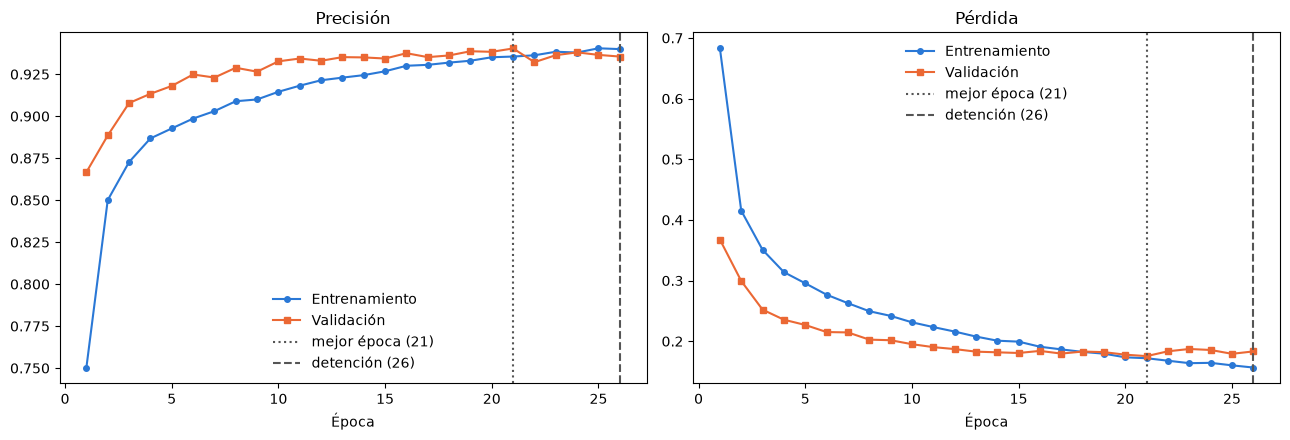

In [6]:
epocas = np.arange(1, len(h["loss"]) + 1)
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for eje, metrica, titulo in ((ejes[0], "accuracy", "Precisión"), (ejes[1], "loss", "Pérdida")):
    eje.plot(epocas, h[metrica], "o-", color="#2a78d6", label="Entrenamiento", markersize=4)
    eje.plot(epocas, h[f"val_{metrica}"], "s-", color="#eb6834", label="Validación", markersize=4)
    eje.axvline(mejor, color="#555555", linestyle=":", label=f"mejor época ({mejor})")
    eje.axvline(epocas[-1], color="#555555", linestyle="--", label=f"detención ({epocas[-1]})")
    eje.set_xlabel("Época"); eje.set_title(titulo); eje.legend(frameon=False)
plt.tight_layout(); plt.show()

## d. Validación del modelo con ejemplos y cotejo

Recién acá se usa el conjunto de prueba oficial de 10.000 imágenes.

Test: accuracy 0.9306 · loss 0.2003
Validación (mejor época): accuracy 0.9403 · diferencia -0.97 p.p.

              precision    recall  f1-score   support

  Remera/top     0.8889    0.8800    0.8844      1000
    Pantalón     0.9990    0.9860    0.9925      1000
        Buzo     0.9243    0.8790    0.9011      1000
     Vestido     0.9194    0.9360    0.9277      1000
      Abrigo     0.8894    0.9010    0.8952      1000
    Sandalia     0.9909    0.9840    0.9875      1000
      Camisa     0.7751    0.8100    0.7922      1000
   Zapatilla     0.9570    0.9800    0.9684      1000
       Bolso     0.9930    0.9870    0.9900      1000
        Bota     0.9777    0.9630    0.9703      1000

    accuracy                         0.9306     10000
   macro avg     0.9315    0.9306    0.9309     10000
weighted avg     0.9315    0.9306    0.9309     10000



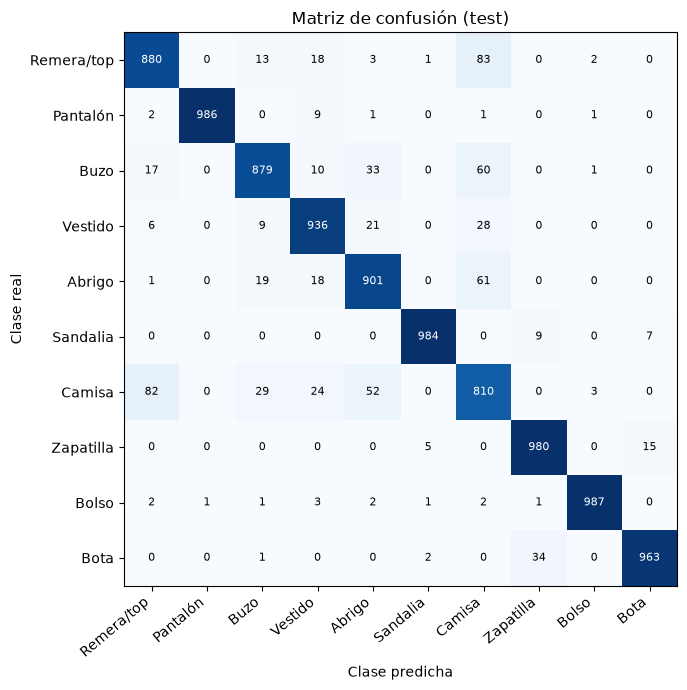

In [7]:
loss_test, acc_test = modelo.evaluate(x_test, y_test_cat, batch_size=128, verbose=0)
probs = modelo.predict(x_test, batch_size=128, verbose=0)
y_pred = probs.argmax(axis=1)
print(f"Test: accuracy {acc_test:.4f} · loss {loss_test:.4f}")
print(f"Validación (mejor época): accuracy {h['val_accuracy'][mejor-1]:.4f} · "
      f"diferencia {100*(acc_test - h['val_accuracy'][mejor-1]):+.2f} p.p.\n")
print(classification_report(y_test, y_pred, target_names=[CLASES[c] for c in range(NUM_CLASES)], digits=4))

matriz = confusion_matrix(y_test, y_pred)
fig, eje = plt.subplots(figsize=(8, 7))
eje.imshow(matriz, cmap="Blues")
for i in range(NUM_CLASES):
    for j in range(NUM_CLASES):
        eje.text(j, i, matriz[i, j], ha="center", va="center", fontsize=8,
                 color="white" if matriz[i, j] > matriz.max() / 2 else "black")
nombres = [CLASES[c] for c in range(NUM_CLASES)]
eje.set_xticks(range(NUM_CLASES), nombres, rotation=40, ha="right"); eje.set_yticks(range(NUM_CLASES), nombres)
eje.set_xlabel("Clase predicha"); eje.set_ylabel("Clase real"); eje.set_title("Matriz de confusión (test)")
plt.tight_layout(); plt.show()

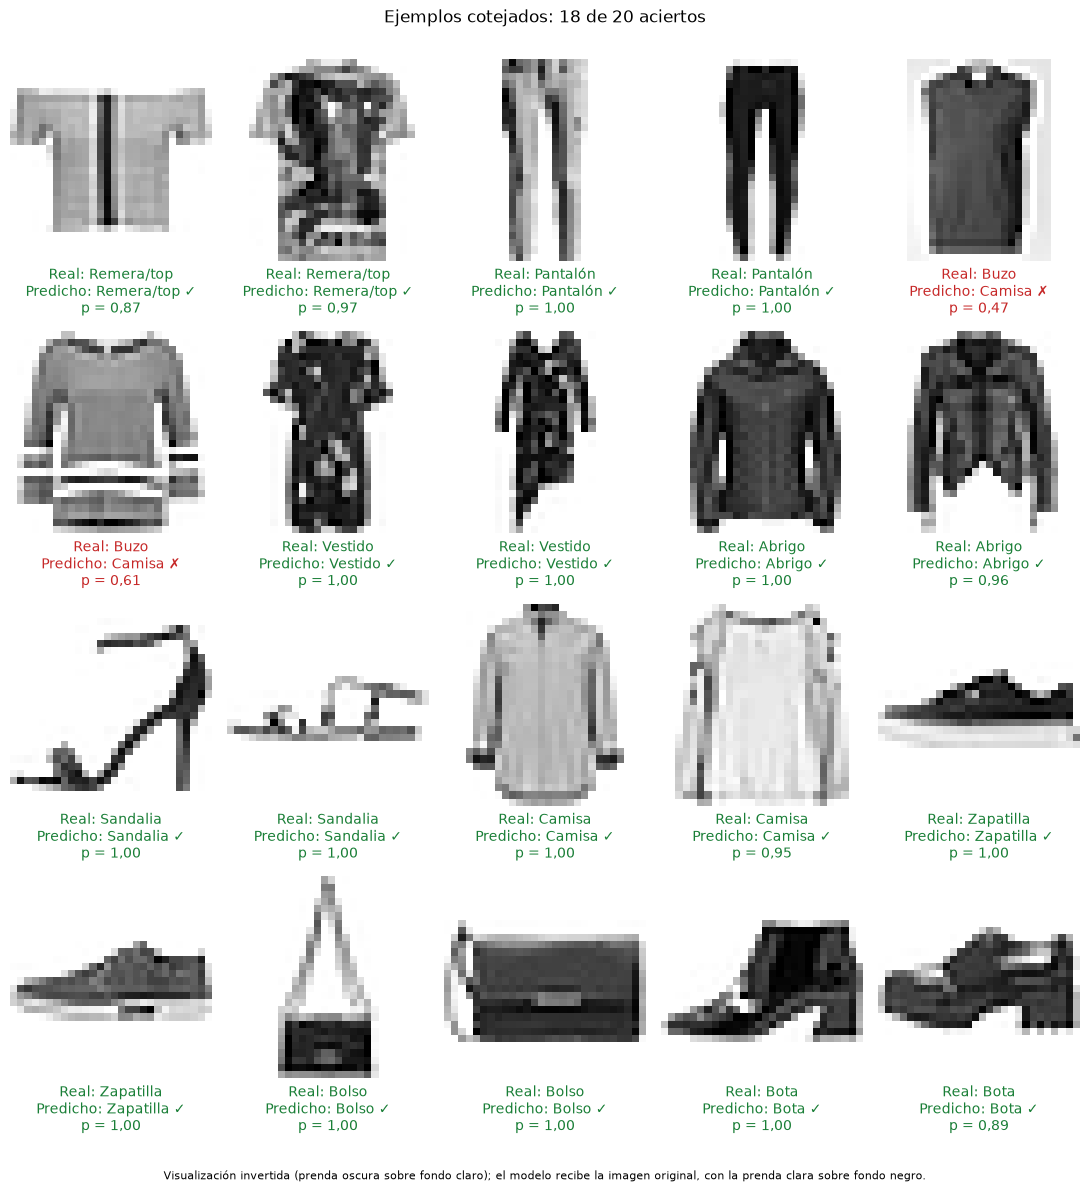

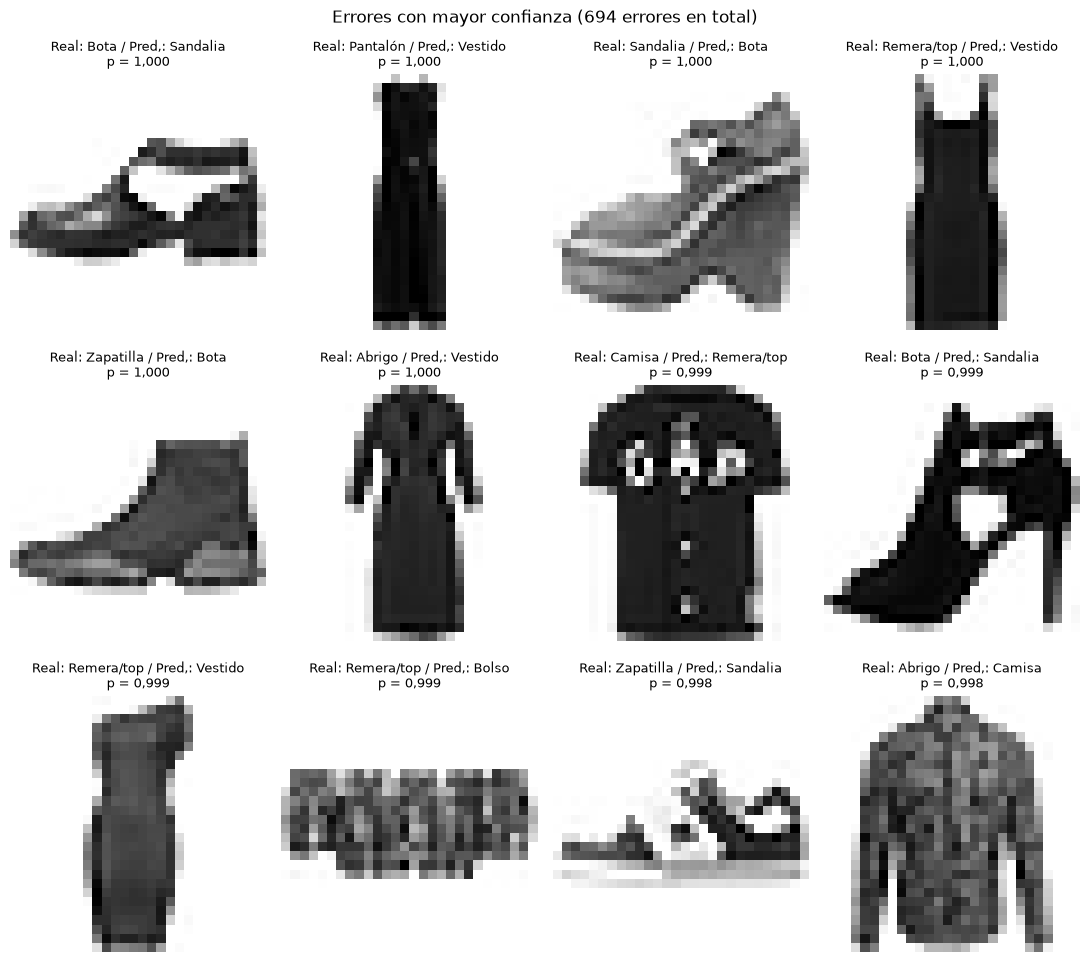

In [8]:
# Ejemplos cotejados: 2 por clase al azar con semilla 42, elegidos sin mirar las predicciones
rng = np.random.default_rng(SEMILLA)
indices = []
for c in range(NUM_CLASES):
    indices.extend(sorted(rng.choice(np.flatnonzero(y_test == c), size=2, replace=False).tolist()))
aciertos = int((y_pred[indices] == y_test[indices]).sum())

fig, ejes = plt.subplots(4, 5, figsize=(11, 12))
for eje, i in zip(ejes.flat, indices):
    ok = y_pred[i] == y_test[i]
    mostrar_imagen(eje, x_test[i])
    eje.set_xlabel(f"Real: {CLASES[y_test[i]]}\nPredicho: {CLASES[y_pred[i]]} {'✓' if ok else '✗'}\n"
                   f"p = {probs[i].max():.2f}".replace(".", ","), color="#1a7f37" if ok else "#c62828")
fig.suptitle(f"Ejemplos cotejados: {aciertos} de {len(indices)} aciertos")
fig.text(0.5, 0.005, EPIGRAFE, ha="center", fontsize=8, wrap=True)
plt.tight_layout(rect=(0, 0.03, 1, 1)); plt.show()

# Los 12 errores con mayor confianza
errores = np.flatnonzero(y_pred != y_test)
peores = errores[np.argsort(-probs[errores, y_pred[errores]], kind="stable")][:12]
fig, ejes = plt.subplots(3, 4, figsize=(11, 10))
for eje, i in zip(ejes.flat, peores):
    mostrar_imagen(eje, x_test[i], f"Real: {CLASES[y_test[i]]} / Pred.: {CLASES[y_pred[i]]}\n"
                                   f"p = {probs[i].max():.3f}".replace(".", ","))
fig.suptitle(f"Errores con mayor confianza ({len(errores)} errores en total)")
plt.tight_layout(); plt.show()

## Predicción sobre una imagen suelta

Mismo preprocesamiento que `src/predecir.py`: escala de grises, 28 × 28 con antialiasing, inversión si el
fondo es claro (media de los bordes > 127) y normalización a [0, 1]. Se prueba con una imagen de test
exportada con fondo blanco.

In [9]:
from PIL import Image


def preparar_imagen(ruta):
    img = Image.open(ruta).convert("L")
    if img.size != (LADO, LADO):
        img = img.resize((LADO, LADO), Image.Resampling.LANCZOS, reducing_gap=3.0)
    pixeles = np.asarray(img, dtype=np.float32)
    bordes = np.concatenate([pixeles[0], pixeles[-1], pixeles[1:-1, 0], pixeles[1:-1, -1]])
    if bordes.mean() > 127:
        pixeles = 255.0 - pixeles
    return (pixeles / 255.0).reshape(1, LADO, LADO, 1)


indice = indices[-2]  # primera bota de la muestra
Image.fromarray(255 - np.round(x_test[indice, :, :, 0] * 255).astype(np.uint8)).save(SALIDAS / "prueba_invertida.png")
p = modelo.predict(preparar_imagen(SALIDAS / "prueba_invertida.png"), verbose=0)[0]
for k, c in enumerate(np.argsort(p)[::-1][:3], start=1):
    print(f"{k}. {CLASES[c]}: " + f"{p[c]:.4f}".replace(".", ","))
assert np.allclose(p, probs[indice], atol=1e-5), "el preprocesamiento no reproduce la predicción"
print(f"Test n.º {indice} (real: {CLASES[y_test[indice]]}) → coincide con la predicción sobre el arreglo original")

1. Bota: 0,9999
2. Sandalia: 0,0001
3. Zapatilla: 0,0000
Test n.º 5630 (real: Bota) → coincide con la predicción sobre el arreglo original


## Verificación contra `outputs/resultados.json`

La corrida es determinística: si el notebook se ejecuta en el mismo entorno que los scripts, las métricas
tienen que coincidir. En Colab el archivo no está y la verificación se omite.

In [10]:
ruta = Path("../outputs/resultados.json")
if ruta.exists():
    r = json.loads(ruta.read_text(encoding="utf-8"))
    ent, val = r["entrenamiento"], r["validacion"]
    comparacion = {
        "épocas ejecutadas": (len(h["val_loss"]), ent["epocas_ejecutadas"]),
        "mejor época": (mejor, ent["mejor_epoca"]),
        "val_loss mejor época": (h["val_loss"][mejor - 1], ent["en_mejor_epoca"]["loss_validacion"]),
        "val_accuracy mejor época": (h["val_accuracy"][mejor - 1], ent["en_mejor_epoca"]["accuracy_validacion"]),
        "accuracy test": (float(acc_test), val["global"]["accuracy_test"]),
        "loss test": (float(loss_test), val["global"]["loss_test"]),
        "aciertos en los 20 ejemplos": (aciertos, val["ejemplos"]["aciertos"]),
        "índices de los 20 ejemplos": (indices, val["ejemplos"]["indices"]),
    }
    todo = True
    for nombre, (nb, js) in comparacion.items():
        ok = nb == js if not isinstance(nb, float) else abs(nb - js) < 1e-6
        todo &= ok
        print(f"{'OK ' if ok else 'DIF'} {nombre}: notebook = {nb} · resultados.json = {js}")
    print("\nCOINCIDE CON resultados.json:", todo)
else:
    print("resultados.json no disponible (por ejemplo, en Colab): se omite la verificación.")

OK  épocas ejecutadas: notebook = 26 · resultados.json = 26
OK  mejor época: notebook = 21 · resultados.json = 21
OK  val_loss mejor época: notebook = 0.1754167526960373 · resultados.json = 0.1754167526960373
OK  val_accuracy mejor época: notebook = 0.9403333067893982 · resultados.json = 0.9403333067893982
OK  accuracy test: notebook = 0.9305999875068665 · resultados.json = 0.9305999875068665
OK  loss test: notebook = 0.20028471946716309 · resultados.json = 0.20028471946716309
OK  aciertos en los 20 ejemplos: notebook = 18 · resultados.json = 18
OK  índices de los 20 ejemplos: notebook = [881, 7868, 4476, 4519, 670, 6721, 1009, 5251, 7304, 7510, 5215, 7780, 4620, 8519, 1820, 3559, 6403, 7907, 5630, 8205] · resultados.json = [881, 7868, 4476, 4519, 670, 6721, 1009, 5251, 7304, 7510, 5215, 7780, 4620, 8519, 1820, 3559, 6403, 7907, 5630, 8205]

COINCIDE CON resultados.json: True
